## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load the dataset
housing = pd.read_csv("housing.csv")

### 1. Create an income_cat column by binning median_income with edges [0, 1.5, 3.0, 4.5, 6.0, np.inf] labeled 1–5. Using StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42), split the data. Report the count of each income_cat value in both the train and test sets.

In [ ]:
housing["income_cat"] = pd.cut(housing["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6.0, np.inf], # divide median_income into 5 groups
                               labels=[1, 2, 3, 4, 5]) # to have approximately the same distribution of income levels.

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42) # splits by income_cat making sure each gets same proportion
for train_index, test_index in split.split(housing, housing["income_cat"]):
    strat_train_set = housing.loc[train_index]
    strat_test_set = housing.loc[test_index]

print("Train set income_cat counts:")
print(strat_train_set["income_cat"].value_counts().sort_index())

print("\nTest set income_cat counts:")
print(strat_test_set["income_cat"].value_counts().sort_index())

# Remove the income_cat attribute so the data is back to its original state
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

Train set income_cat counts:
income_cat
1     657
2    5265
3    5789
4    2911
5    1890
Name: count, dtype: int64

Test set income_cat counts:
income_cat
1     165
2    1316
3    1447
4     728
5     472
Name: count, dtype: int64


#### 2. Build a ColumnTransformer with: numeric pipeline = SimpleImputer(strategy="median") -> StandardScaler(); categorical pipeline = OneHotEncoder(handle_unknown="ignore") on ocean_proximity. Fit-transform the training set and report the shape of the resulting array.

In [ ]:
housing_train = strat_train_set.drop("median_house_value", axis=1) # training set, so we need to predict the median cost
housing_labels = strat_train_set["median_house_value"].copy() # output

housing_num = housing_train.drop("ocean_proximity", axis=1) # separate numerical columns from categorical

from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="median")), # fill null values with median
    ('std_scaler', StandardScaler()), # standardize the numerical values (Z score), mean = 0 and std = 1
]) # perform pre-processing steps in this order

num_attribs = list(housing_num)
cat_attribs = ["ocean_proximity"]

full_pipeline = ColumnTransformer([ # apply different preprocessing to different columns
    ("num", num_pipeline, num_attribs),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_attribs),
])

housing_prepared = full_pipeline.fit_transform(housing_train) # actual preprocessing step
print("Shape of resulting array:", housing_prepared.shape) # 16k houses. 13 features

Shape of resulting array: (16512, 13)


### 3. Using this pipeline, train LinearRegression(), DecisionTreeRegressor(random_state=42), and RandomForestRegressor(n_estimators=100, random_state=42). Using cross_val_score with cv=5 and scoring="neg_root_mean_squared_error", report the mean ± std RMSE for each model.

In [ ]:
models = {
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(random_state=42),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=100, random_state=42)
}

for name, model in models.items():
    scores = cross_val_score(model, housing_prepared, housing_labels,
                             scoring="neg_root_mean_squared_error", cv=5)
    rmse_scores = -scores
    print(f"{name}:")
    print(f"  Mean RMSE: {rmse_scores.mean():.4f}")
    print(f"  Std RMSE:  {rmse_scores.std():.4f}\n")
    # std rmse tells how much the RMSE changed between the 5 folds. lower the more consistent

LinearRegression:
  Mean RMSE: 69218.4543
  Std RMSE:  689.5020

DecisionTreeRegressor:
  Mean RMSE: 70629.2418
  Std RMSE:  1447.6599

RandomForestRegressor:
  Mean RMSE: 49941.7336
  Std RMSE:  760.8980



#### 4. Run GridSearchCV on RandomForestRegressor over n_estimators ∈ {50, 100, 200} and max_features ∈ {2, 4, 6, 8} with cv=5. Report the best hyperparameter combination and its CV RMSE.

In [ ]:
param_grid = [ # finding the best parameters for a model
    {'n_estimators': [50, 100, 200], 'max_features': [2, 4, 6, 8]},
]

forest_reg = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(forest_reg, param_grid, cv=5,
                           scoring='neg_root_mean_squared_error',
                           return_train_score=True)

grid_search.fit(housing_prepared, housing_labels)

best_params = grid_search.best_params_
best_rmse = -grid_search.best_score_

print("Best Hyperparameters:", best_params)
print("Best CV RMSE:", best_rmse)

Best Hyperparameters: {'max_features': 8, 'n_estimators': 200}
Best CV RMSE: 49015.18905532731


### 5. Evaluate the best tuned model on the held-out test set. Report Test RMSE, MAE, and R².

In [ ]:
final_model = grid_search.best_estimator_

X_test = strat_test_set.drop("median_house_value", axis=1)
y_test = strat_test_set["median_house_value"].copy()

X_test_prepared = full_pipeline.transform(X_test)
final_predictions = final_model.predict(X_test_prepared)

final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_mae = mean_absolute_error(y_test, final_predictions)
final_r2 = r2_score(y_test, final_predictions)

print(f"Test RMSE: {final_rmse:.4f}")
print(f"Test MAE: {final_mae:.4f}")
print(f"Test R²: {final_r2:.4f}") # how well model explains variations in the prices. higher the better

Test RMSE: 46563.7820
Test MAE: 30805.8926
Test R²: 0.8336


### 6. Using only NumPy, implement linear regression via the Normal Equation (θ = (XᵀX)⁻¹Xᵀy) with median_income and housing_median_age (plus a bias/intercept term) as the only two features to predict median_house_value. Report your computed θ values and their % difference from sklearn.linear_model.LinearRegression fit on the same two features.

In [7]:
# NumPy implementation
X_np = strat_train_set[['median_income', 'housing_median_age']].values
X_np_b = np.c_[np.ones((len(X_np), 1)), X_np] # add bias term x0 = 1
y_np = strat_train_set['median_house_value'].values

theta_best = np.linalg.inv(X_np_b.T.dot(X_np_b)).dot(X_np_b.T).dot(y_np)

print("Computed θ values (NumPy):", theta_best)

# Sklearn implementation
lin_reg_subset = LinearRegression()
lin_reg_subset.fit(X_np, y_np)
theta_sklearn = np.concatenate([[lin_reg_subset.intercept_], lin_reg_subset.coef_])

print("Computed θ values (Sklearn):", theta_sklearn)

# Percentage difference
diff = np.abs(theta_best - theta_sklearn) / np.abs(theta_sklearn) * 100
print("% Difference from Sklearn:", diff)

Computed θ values (NumPy): [-10706.89088263  43041.07749557   1776.05349833]
Computed θ values (Sklearn): [-10706.89088263  43041.07749557   1776.05349833]
% Difference from Sklearn: [2.20856479e-13 0.00000000e+00 6.40109309e-13]


### 7. Plot a geographic scatter plot (longitude vs latitude, point size ∝ population, color ∝ median_house_value, alpha=0.4).

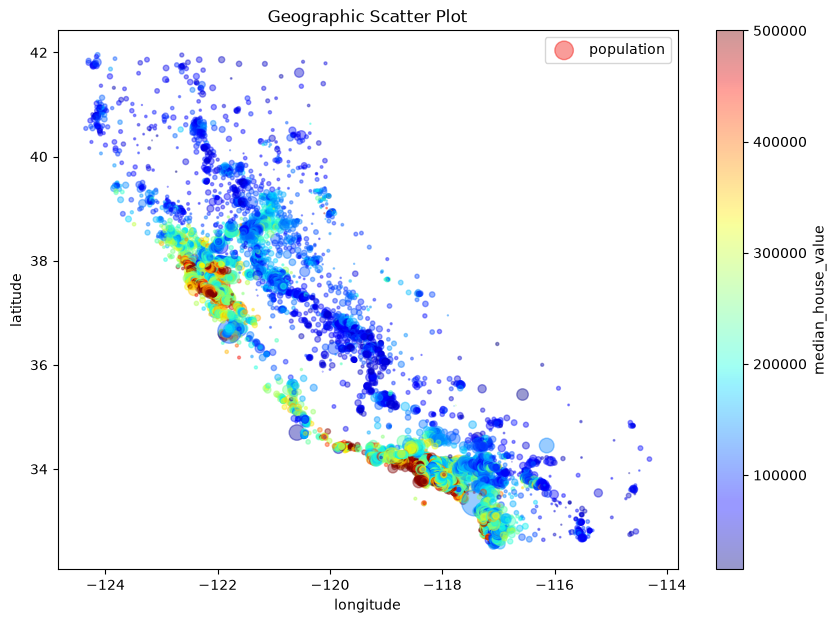

In [13]:
housing.plot(kind="scatter", x="longitude", y="latitude", alpha=0.4,
             s=housing["population"]/100, label="population", figsize=(10,7),
             c="median_house_value", cmap=plt.get_cmap("jet"), colorbar=True,
             sharex=False)
plt.title("Geographic Scatter Plot")
plt.legend()
plt.show()
# larger circles -> higher population
# blue -> low cost

### 8. Plot a histogram of median_house_value.

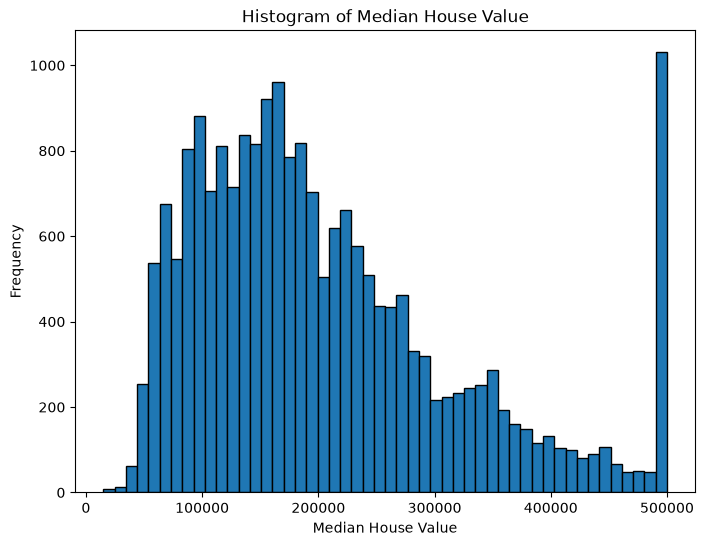

In [9]:
plt.figure(figsize=(8, 6))
plt.hist(housing['median_house_value'], bins=50, edgecolor='black')
plt.title("Histogram of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

### 9. Plot predicted vs. actual median_house_value on the test set (scatter plot with a red dashed diagonal reference line).

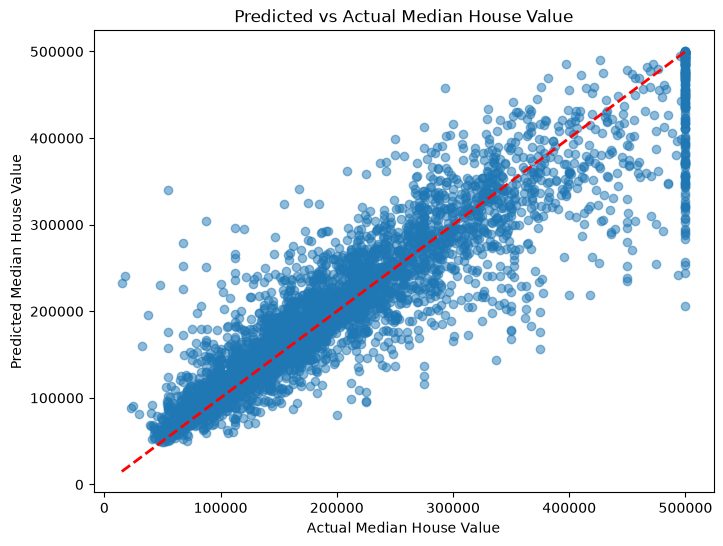

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, final_predictions, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title("Predicted vs Actual Median House Value")
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.show()

### 10. Plot the top-10 feature importances from the tuned Random Forest as a horizontal bar chart.

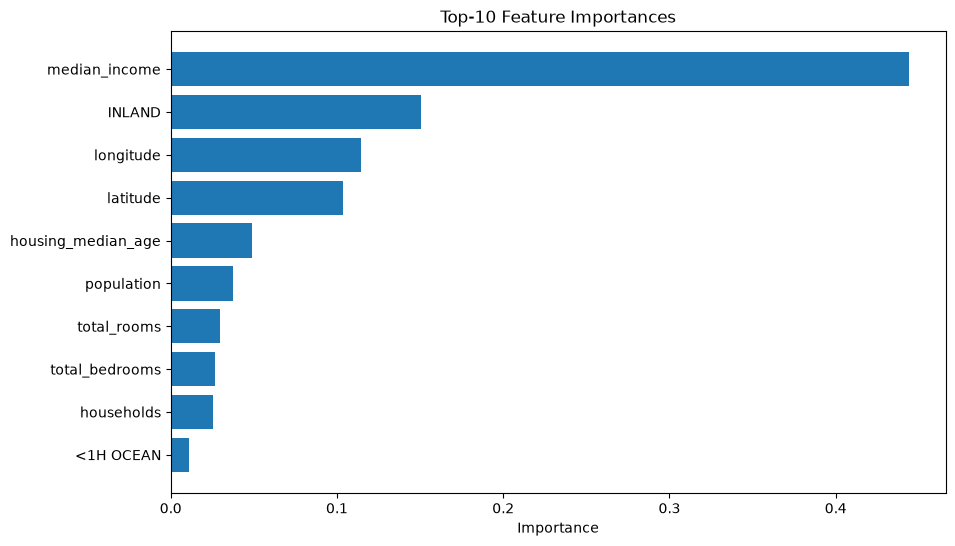

In [11]:
feature_importances = grid_search.best_estimator_.feature_importances_

extra_attribs = []
cat_encoder = full_pipeline.named_transformers_["cat"]
cat_one_hot_attribs = list(cat_encoder.categories_[0])
attributes = num_attribs + cat_one_hot_attribs

importance_df = pd.DataFrame({
    'Feature': attributes,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'][::-1], importance_df['Importance'][::-1])
plt.title("Top-10 Feature Importances")
plt.xlabel("Importance")
plt.show()